[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jalonso1979/puremacro/blob/main/curso/notebooks/T01_B_measurement_and_cycles.ipynb)

> **Google Colab note**: the next cell installs `puremacro` and, if needed, fetches only the `curso/notebooks` folder (helpers, frozen data and models) from the public repository [jalonso1979/puremacro](https://github.com/jalonso1979/puremacro). It does not ask for Google Drive access.

[A: Data](T01_A_data_panels.ipynb) · [B: Measurement and cycles](T01_B_measurement_and_cycles.ipynb) · [C: Stylized facts](T01_C_stylized_facts.ipynb)

In [1]:
# Environment setup: Google Colab, local install or Juno (iPad)
import os
import sys
from pathlib import Path

def _safe_probe(p, is_dir=None):
    """Does the path exist? Never raises OSError/PermissionError in the Juno sandbox."""
    try:
        p = Path(p)
        if is_dir is True:
            return p.is_dir()
        if is_dir is False:
            return p.is_file()
        return p.exists()
    except (OSError, PermissionError, TypeError, ValueError):
        return False

if "google.colab" in sys.modules:
    !pip install -q "puremacro>=4.8.1,<5"
    if not _safe_probe(Path.cwd() / "_nbstyle.py", is_dir=False):
        # Partial clone of the public repository: only curso/notebooks, no history
        _repo = Path("/content/puremacro")
        if not _safe_probe(_repo, is_dir=True):
            !git clone -q --depth 1 --filter=blob:none --sparse https://github.com/jalonso1979/puremacro.git {_repo}
        !git -C {_repo} sparse-checkout set curso/notebooks 2>&1 | tail -n 2
        os.chdir(_repo / "curso/notebooks")

# Put the course helpers folder (_nbstyle, _datos) on sys.path, without leaving the sandbox
_candidates = [Path.cwd(), Path.cwd() / "notebooks", Path.cwd() / "curso/notebooks"]
try:
    _candidates.insert(0, Path(__file__).resolve().parent)  # Juno defines __file__
except (NameError, OSError):
    pass
for _c in _candidates:
    if _safe_probe(_c / "_nbstyle.py", is_dir=False):
        if str(_c) not in sys.path:
            sys.path.insert(0, str(_c))
        break

# Inline figures and the course style
%matplotlib inline
try:
    import _nbstyle
    _nbstyle.apply_style()
except ImportError:
    pass

# Module 1B — Measurement, vintages and the position in the cycle

**Supplementary course · puremacro**

A gives us observations, not an output gap. Can a change in measured GDP be an accounting choice, a revision, or a change in the economy? And could a policymaker have seen the signal at the time?

### Learning objectives
1. Audit real/nominal identities, seasonal adjustment, labour units and temporal aggregation.
2. Distinguish reference periods from vintage dates; run both **Mankiw–Shapiro (1986)** revision regressions on growth rates.
3. Compare HP, Hamilton, Baxter–King, Christiano–Fitzgerald and first differences, including their different endpoints and estimands.
4. Separate revisions due to data from revisions due to a filter's sample endpoint.
5. Read GDP, industrial production and unemployment together, with the **Sahm rule** as a U.S. signal and an explicitly exploratory international diagnostic.

**Route:** measurement → vintages → filters → real-time uncertainty → cycle dashboard. This prepares the measurement choices used in **C**, where we finally evaluate stylized facts. All results below use frozen data. The last date in a file is printed, not assumed to be today.

In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import _nbstyle
from _datos import ruta_dato
from _t01 import CONTRACT, load_panel, wide_panel, coverage, regular_block
_nbstyle.apply_style()
cols = _nbstyle.palette(6)
LANG = "en"
def tr(en, es):
    return es if LANG == "es" else en
manifest = json.loads(ruta_dato("t01_manifest.json").read_text())
print(tr("Snapshot assembly (UTC):", "Ensamblado de las copias (UTC):"), manifest["assembled_utc"])

Snapshot assembly (UTC): 2026-10-07T23:48:52.985790+00:00


In [3]:
q = wide_panel(load_panel("Q", variables=CONTRACT["Q"]))  # the quarterly series T01_A promises B and C
q = q[q.gdp.notna().groupby(level="code").transform("any")]  # economies with quarterly national accounts
m = wide_panel(load_panel("M", variables=["ip", "urate"]))  # the two monthly series this notebook reads
for v in ["gdp", "cons_hh", "cons_gov", "inv", "capform", "exports", "imports"]:
    q[v + "_real"] = 100 * q[v] / q[v + "_defl"]
from puremacro.data import hp_filter
from puremacro.cycles import hamilton_filter, baxter_king_filter, christiano_fitzgerald_filter

## 1. What is measured: identities, prices and labour

At current prices, the expenditure identity uses **gross capital formation** (fixed investment plus inventories and valuables), not fixed investment alone:
$$Y^N=C^N+G^N+I^N_{\rm total}+X^N-M^N.$$
Chain-linked volumes generally do not add. A common reference year changes index levels; it does not restore additivity or purchasing-power comparability. Changes in household durables' classification also move $\sigma(c)/\sigma(y)$ without changing household behavior.

A plausible hours-per-worker ratio is a diagnostic, not enough on its own to prove a unit correction. The companion documents the source checks. Here the stored `hours_factor` tells us which repairs were already made. Measurement of the economy and measurement of the market sector are separate choices, particularly for U.S./Japan productivity comparisons.

In [4]:
identity = q[["gdp", "cons_hh", "cons_gov", "capform", "exports", "imports"]].dropna()
identity["residual_pct"] = 100*(identity.gdp - identity.cons_hh - identity.cons_gov
                                - identity.capform - identity.exports + identity.imports)/identity.gdp
vr = q[[v + "_real" for v in ["gdp", "cons_hh", "cons_gov", "capform", "exports", "imports"]]].dropna()
vr["residual_pct"] = 100*(vr.gdp_real-vr.cons_hh_real-vr.cons_gov_real-vr.capform_real-vr.exports_real+vr.imports_real)/vr.gdp_real
display(pd.DataFrame({"nominal_abs_residual_pct": identity.residual_pct.abs().groupby("code").median(),
                      "volume_abs_residual_pct": vr.residual_pct.abs().groupby("code").median()}).round(3))
repairs = q.hours_factor.groupby("code").first().dropna()
display(repairs[repairs.ne(1)].rename("stored_hours_factor").to_frame())
print(tr("Residuals are measurements to inspect, not an excuse to force the accounts to close.",
         "Los residuos se inspeccionan; no justifican forzar el cierre de las cuentas."))

,nominal_abs_residual_pct,volume_abs_residual_pct
code,,
ARG,0.448,0.478
ARM,1.263,NaN
AUS,0.335,0.825
AUT,0.322,0.407
BEL,0.000,0.160
BGR,0.404,1.223
BIH,8.637,4.545
BRA,0.665,0.220
CAN,0.087,0.254


,stored_hours_factor
code,
CHL,13.0


Residuals are measurements to inspect, not an excuse to force the accounts to close.


### 1.1 Aggregation can create persistence

For a random walk observed monthly, growth in non-overlapping three-month averages has first-order autocorrelation $4/19$, even though monthly increments are independent. Growth between quarter-end observations does not have this particular averaging effect. The simulation is explicitly synthetic; it explains a measurement mechanism, not an empirical fact about a country.

Seasonal adjustment is a separate issue. The QNA metadata distinguish provider adjustment from course adjustment. Year-on-year differences can remove a stable seasonal pattern but introduce overlapping observations and do not replace a documented seasonal-adjustment procedure.

In [5]:
rng = np.random.default_rng(20261004)
walk = np.cumsum(rng.normal(size=300000)).reshape(-1, 3)
working = pd.Series(walk.mean(axis=1)).diff().autocorr()
end_month = pd.Series(walk[:, -1]).diff().autocorr()
display(pd.Series({"quarterly averages": working, "quarter-end observations": end_month,
                   "theory: 4/19": 4/19}, name="rho_1").to_frame())
assert abs(working - 4/19) < .02 and abs(end_month) < .02

,rho_1
quarterly averages,0.211630
quarter-end observations,0.000457
theory: 4/19,0.210526


## 2. Two dates: the quarter and the edition

Write $y_t^{(v)}$: reference quarter $t$, archive edition $v$. A latest-release file has only one column of this triangle and cannot reconstruct the information available in 2008. The OECD archive here has monthly editions, not exact official first-release timestamps. **First observed in this archive** is the defensible description of a preliminary value.

We retain every edition, screen seasonal contamination, and apply the same quarterly-dummy adjustment within each edition. The coefficients use only observations present in that edition (a pre-2020 fitting window where available). This avoids deleting early unadjusted editions and promoting a revision years later to “first release.” It is a transparent teaching adjustment, not a substitute for X-13's calendar effects and outlier treatment. The detailed companion preserves the X-13 comparison and the nine-component revision tests.

In [6]:
from puremacro.fetch.realtime import VintagePanel, seasonal_signature, SEASONAL_WINDOW, SEASONAL_MIN_OBS
raw = pd.read_csv(ruta_dato("oecd_stes_vintages_gdp.csv.gz"), dtype={"edition": str})
vintage_data = pd.DataFrame({
    "country": raw.code.astype(str), "variable": raw.variable.astype(str),
    "date": pd.PeriodIndex(raw.date.astype(str), freq="Q").to_timestamp(),
    "vintage": pd.to_datetime(raw.edition, format="%Y%m"), "value": raw.value,
    "provider": pd.Categorical(["oecd_stes"]*len(raw)),
    "series_id": pd.Categorical(raw.code.astype(str) + ".Q.B1GQ_Q"),
    "units": pd.Categorical(["level"]*len(raw)),
})
raw_panel = VintagePanel(df=vintage_data)
print(tr("Archive coverage:", "Cobertura del archivo:"))
display(raw_panel.coverage().head())

Archive coverage:


,country,variable,provider,series_id,n_obs,n_vintages,n_periods,first_date,last_date,first_vintage,last_vintage
0,AUS,gdp_real,oecd_stes,AUS.Q.B1GQ_Q,68505,331,267,1959-07-01,2026-01-01,1999-02-01,2026-08-01
1,AUT,gdp_real,oecd_stes,AUT.Q.B1GQ_Q,27680,331,250,1964-01-01,2026-04-01,1999-02-01,2026-08-01
2,BEL,gdp_real,oecd_stes,BEL.Q.B1GQ_Q,27397,331,186,1980-01-01,2026-04-01,1999-02-01,2026-08-01
3,BRA,gdp_real,oecd_stes,BRA.Q.B1GQ_Q,21347,263,141,1991-01-01,2026-01-01,2004-09-01,2026-08-01
4,CAN,gdp_real,oecd_stes,CAN.Q.B1GQ_Q,58150,331,262,1961-01-01,2026-04-01,1999-02-01,2026-08-01


In [7]:
def deseasonalize_editions(p, sig=None, window=SEASONAL_WINDOW,
                           min_obs=SEASONAL_MIN_OBS):
    """Adjust every edition independently, retaining all rows; return panel and receipt."""
    lo, hi = pd.Timestamp(window[0]), pd.Timestamp(window[1])
    pieces, short_n = [], 0
    for (country, var), sub in p.df.groupby(["country", "variable"], sort=True):
        piv = (sub.pivot_table(index="date", columns="vintage", values="value")
                  .sort_index())
        lg = np.log(piv)
        g = lg.diff()
        q = pd.Index(g.index.quarter)
        inside = (g.index >= lo) & (g.index < hi)
        qi = q[inside]
        m = g[inside].groupby(qi).mean().reindex([1, 2, 3, 4])
        n_q = g[inside].groupby(qi).count().reindex([1, 2, 3, 4]).fillna(0)
        # The very few editions that do not reach min_obs inside the window —
        # the earliest ones, ending in 1998 — are estimated on their whole
        # sample, which for them is entirely pre-pandemic anyway.
        short = n_q.sum() < min_obs
        if short.any():
            whole = g.groupby(q).mean().reindex([1, 2, 3, 4])
            mask = short.to_numpy()
            m.loc[:, mask] = whole.loc[:, mask]
            short_n += int(short.sum())
        m = m.fillna(0.0)
        m = m - m.mean(axis=0)      # centred: the profile goes, the mean stays
        factor = m.cumsum()          # periodic by construction: factor[4] = 0
        key = pd.MultiIndex.from_arrays(
            [sub["date"].dt.quarter, sub["vintage"]])
        pieces.append(sub.assign(
            value=sub["value"].to_numpy()
            * np.exp(-factor.stack().reindex(key).to_numpy())))
    out = pd.concat(pieces, ignore_index=True)
    adjusted = VintagePanel(df=out,
                            metadata={**p.metadata,
                                      "seasonal": "quarterly dummies within edition",
                                      "short_editions": short_n})
    # `sig` arrives ready-made because the cell already computed it for the
    # screen: scoring eleven thousand editions twice is a quarter of a second on
    # a desktop and considerably more on a tablet, for exactly the same numbers.
    before = seasonal_signature(p) if sig is None else sig
    after = seasonal_signature(adjusted)
    receipt = pd.concat(
        [before.groupby("country")["seasonal_range"].max().rename("range_before"),
         after.groupby("country")["seasonal_range"].max().rename("range_after"),
         before.groupby("country")["unadjusted"].sum().rename("flagged")],
        axis=1)
    return adjusted, receipt

In [8]:
signature = seasonal_signature(raw_panel)
vintages, seasonal_receipt = deseasonalize_editions(raw_panel, sig=signature)
assert len(vintages.df) == len(raw_panel.df)
print(tr("Editions flagged / all editions:", "Ediciones marcadas / todas las ediciones:"),
      int(signature.unadjusted.sum()), "/", raw_panel.df.groupby(["country", "vintage"]).ngroups)
display(seasonal_receipt.sort_values("range_before", ascending=False).head(10).round(3))
triangle = vintages.triangle("MEX", transform="log_diff_pct")
display(triangle.loc["2008":"2009"].iloc[:, -8:].round(2))
# Free the unadjusted copies before estimating the international panel.
del raw, vintage_data, raw_panel

Editions flagged / all editions: 501 / 11503


,range_before,range_after,flagged
country,,,
TUR,61.754,0.0,76
CZE,29.778,0.0,38
SWE,28.691,0.0,76
POL,22.843,0.0,53
HUN,19.636,0.0,24
AUT,17.747,0.0,48
ISL,16.671,0.0,30
SVK,12.784,0.0,56
MEX,10.834,0.0,72


vintage,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01
date,,,,,,,,
2008-01-01,0.30,0.25,0.25,0.25,0.25,0.23,0.23,0.23
2008-04-01,0.92,0.99,0.99,0.99,0.99,1.01,1.01,1.01
2008-07-01,-0.20,-0.23,-0.23,-0.23,-0.23,-0.24,-0.24,-0.24
2008-10-01,-1.83,-1.81,-1.81,-1.81,-1.81,-1.80,-1.80,-1.80
2009-01-01,-6.10,-6.08,-6.08,-6.08,-6.09,-6.09,-6.09,-6.09
2009-04-01,-1.41,-1.46,-1.46,-1.46,-1.45,-1.46,-1.46,-1.46
2009-07-01,3.24,3.26,3.26,3.26,3.26,3.26,3.26,3.26
2009-10-01,1.93,1.94,1.94,1.94,1.94,1.95,1.95,1.95


### 2.1 Mankiw–Shapiro: news, noise, both or neither

Use quarter-on-quarter log growth calculated **inside each edition**, not a difference between levels from two vintages with different base years. Let $p_t$ be the first observed growth estimate, $f_t$ the latest available estimate, and $r_t=f_t-p_t$.

$$r_t=\alpha_N+\beta_Np_t+e_t,\qquad r_t=\alpha_E+\beta_Ef_t+u_t.$$

Pure unbiased news implies $(\alpha_N,\beta_N)=(0,0)$; pure unbiased noise implies $(\alpha_E,\beta_E)=(0,0)$. We report both slope tests, the mean-revision test and **joint intercept/slope HAC Wald tests**. Failure to reject is compatibility with a restricted model, not proof that revisions contain only news or only noise. Rejecting both leaves room for mixtures and bias.

To reduce left censoring and immature “finals”, retain first appearances 1–6 months after the reference quarter and require at least 12 months between first and last estimates. The latest estimate is still revisable. We then retain the longest contiguous block (at least 24 quarters) so HAC lags respect the calendar. Excluded counts are displayed. [Mankiw and Shapiro (1986)](https://www.nber.org/papers/w1939).

In [9]:
from scipy.stats import chi2
from puremacro.vintages import mankiw_shapiro

def joint_hac_pvalue(revision, regressor):
    y, x = np.asarray(revision), np.asarray(regressor)
    X = np.column_stack([np.ones(len(y)), x])
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    score = X*(y-X@beta)[:, None]
    bandwidth = int(np.floor(4*(len(y)/100)**(2/9)))
    meat = score.T@score
    for lag in range(1, bandwidth+1):
        cross = score[lag:].T@score[:-lag]
        meat += (1-lag/(bandwidth+1))*(cross+cross.T)
    bread = np.linalg.inv(X.T@X)
    cov = bread@meat@bread * len(y)/(len(y)-X.shape[1])
    return float(chi2.sf(beta@np.linalg.pinv(cov)@beta, 2))

def mature_pairs(one, country):
    tri = one.triangle(country, transform="log_diff_pct")
    rows = []
    for date, values in tri.iterrows():
        values = values.dropna()
        if len(values) < 2:
            continue
        first, last = values.index[0], values.index[-1]
        lag = first.to_period("M").ordinal - date.to_period("Q").asfreq("M", "end").ordinal
        mature = (last.to_period("M").ordinal-first.to_period("M").ordinal) >= 12
        if 1 <= lag <= 6 and mature:
            rows.append({"date":date, "preliminary":values.iloc[0], "final":values.iloc[-1]})
    return pd.DataFrame(rows), len(tri)

rows = []
for country, data in vintages.df.groupby("country", sort=True):
    if country == "EA20":  # an aggregate, not one more independent country
        continue
    pairs, total = mature_pairs(VintagePanel(df=data), country)
    eligible = len(pairs)
    block = (regular_block(pairs.set_index("date"), ["preliminary", "final"], min_obs=24)
             if not pairs.empty else None)
    pairs = block if block is not None else pairs.iloc[:0]
    row = {"code": country, "candidate_quarters": total, "eligible_mature_pairs": eligible, "n": len(pairs), "excluded": total-len(pairs)}
    if len(pairs) >= 24:
        result = mankiw_shapiro(pairs.preliminary, pairs.final, hac_lags="auto", transform="log_diff_pct")
        revision = pairs.final-pairs.preliminary
        pn = joint_hac_pvalue(revision, pairs.preliminary)
        pe = joint_hac_pvalue(revision, pairs.final)
        row.update(mean_revision=result.mean_revision, p_bias=result.p_mean_revision,
                   beta_preliminary=result.beta_on_preliminary, p_slope_news=result.p_beta_on_preliminary,
                   beta_final=result.beta_on_final, p_slope_noise=result.p_beta_on_final,
                   p_joint_news=pn, p_joint_noise=pe,
                   compatible=("both" if pn>=.05 and pe>=.05 else "news" if pn>=.05 else "noise" if pe>=.05 else "neither"))
    else:
        row["compatible"] = "insufficient observations"
    rows.append(row)
ms = pd.DataFrame(rows).set_index("code")
display(ms.round(3))
display(ms.compatible.value_counts().rename("countries").to_frame())
assert (ms.n + ms.excluded == ms.candidate_quarters).all()

,candidate_quarters,eligible_mature_pairs,n,excluded,mean_revision,p_bias,beta_preliminary,p_slope_news,beta_final,p_slope_noise,p_joint_news,p_joint_noise,compatible
code,,,,,,,,,,,,,
AUS,267,107,107,160,0.090,0.002,-0.057,0.120,0.050,0.274,0.001,0.001,neither
AUT,250,107,107,143,0.071,0.187,-0.032,0.707,0.152,0.005,0.432,0.001,news
BEL,186,107,106,80,0.147,0.002,-0.065,0.012,-0.010,0.828,0.000,0.002,neither
BRA,141,84,56,85,0.061,0.267,-0.040,0.071,0.057,0.414,0.171,0.241,both
CAN,262,108,108,154,0.067,0.023,-0.070,0.000,-0.027,0.619,0.000,0.085,noise
CHE,185,107,107,78,0.155,0.003,-0.171,0.000,0.037,0.844,0.000,0.001,neither
CHL,125,62,62,63,0.021,0.675,-0.072,0.005,-0.024,0.206,0.015,0.375,noise
COL,85,22,0,85,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,insufficient observations
CRI,142,20,0,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,insufficient observations


,countries
compatible,
neither,15
noise,9
both,8
news,7
insufficient observations,2


**Read the tests.** Compare the slope-only and joint results before telling a “news versus noise” story: a nonzero average revision can reject an unbiased model even if its slope restriction survives. Cross-country counts are descriptive; dozens of 5% tests create multiple-testing risk. Change the maturity horizon and the first-appearance rule before treating the classification as robust. The longer companion retains the original archive-wide specification and shows why discarding unadjusted editions changes the question.

## 3. Filters answer different questions

Let $x_t=100\log Y_t$. HP chooses a smooth trend by minimizing
$$\sum_t(x_t-\tau_t)^2+\lambda\sum_t(\Delta^2\tau_t)^2.$$
The quarterly convention here is $\lambda=1600$; frequency must be specified. Hamilton regresses $x_t$ on a constant and $x_{t-8},\ldots,x_{t-11}$. BK approximates a 6–32-quarter band and discards 12 observations at each edge. CF approximates that band under its random-walk assumptions and retains endpoints, which remain revisable. First differences measure **growth**, not an output gap.

Full-sample Hamilton coefficients use future observations for early residuals even though its regressors are lagged. Two-sided HP and CF also look ahead. A method that returns a number at the last date is not thereby a real-time or structural estimate of potential output. [Hamilton (2018)](https://www.nber.org/papers/w23429).

,n,first,last,sd_common_window
HP,100,1995-01-01,2019-10-01,1.966962
Hamilton,89,1997-10-01,2019-10-01,3.692804
BK,76,1998-01-01,2016-10-01,1.819951
CF,100,1995-01-01,2019-10-01,1.909033


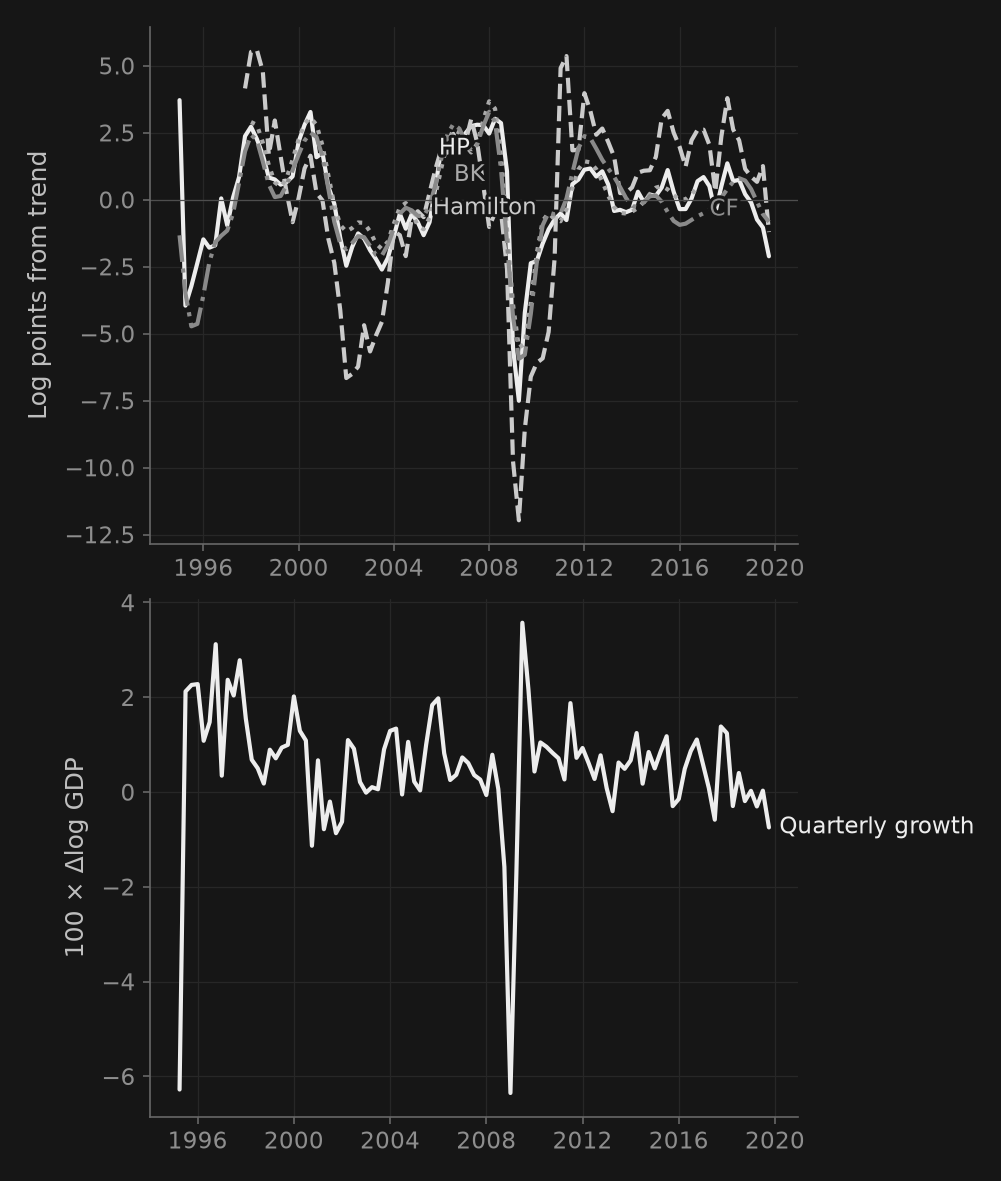

In [10]:
country = "MEX"  # ← compare the same country and window under every method
sample = regular_block(q.loc[country], ["gdp_real"], start="1995", end="2019", min_obs=60)
x = 100*np.log(sample.gdp_real)
filtered = pd.DataFrame({
    "HP": hp_filter(x, lamb=1600)[0],
    "Hamilton": hamilton_filter(x, h=8, p=4)[0],
    "BK": baxter_king_filter(x, low=6, high=32, K=12)[0],
    "CF": christiano_fitzgerald_filter(x, low=6, high=32)[0],
})
common = filtered.dropna()
display(pd.DataFrame({"n": filtered.count(), "first": filtered.apply(lambda s:s.first_valid_index()),
                      "last": filtered.apply(lambda s:s.last_valid_index()),
                      "sd_common_window": common.std()}))
fig, axes = _nbstyle.figura(2, 1)
for j, name in enumerate(filtered):
    axes[0].plot(filtered.index, filtered[name], color=cols[j], ls=["-","--",":","-."][j], label=name)
axes[0].axhline(0, color=cols[-1], lw=.6)
axes[0].set_ylabel(tr("Log points from trend", "Puntos log desde tendencia"))
_nbstyle.etiquetar(axes[0])
axes[1].plot(x.index, x.diff(), color=cols[0], label=tr("Quarterly growth", "Crecimiento trimestral"))
axes[1].set_ylabel(tr("100 × Δlog GDP", "100 × Δlog PIB"))
_nbstyle.etiquetar(axes[1]); plt.show()

### 3.1 A filter can manufacture apparent cycles

An integrated series has no observed “true gap” just because its growth innovations are independent. Filtering a random walk can yield a persistent residual; that persistence cannot by itself validate an RBC propagation mechanism. Calibrate a model to moments only after applying the same measurement and filtering choices to model and data.

In [11]:
rng = np.random.default_rng(142)
synthetic = pd.Series(np.cumsum(rng.normal(size=400)))
synthetic_hp = pd.Series(hp_filter(synthetic, lamb=1600)[0])
display(pd.Series({"innovation rho_1": synthetic.diff().autocorr(),
                   "HP residual rho_1": synthetic_hp.autocorr()}, name="synthetic_example").to_frame())

,synthetic_example
innovation rho_1,-0.026139
HP residual rho_1,0.642411


## 4. Was the gap knowable at the time?

At an edition's last available quarter $t$, compute three HP gaps with the same starting date:

- $g_t^{RT}$: that edition, ending at $t$.
- $g_t^{P}$: the latest edition truncated at $t$ (pseudo real time).
- $g_t^{F}$: the latest edition with its later observations.

Then $g_t^F-g_t^{RT}=(g_t^P-g_t^{RT})+(g_t^F-g_t^P)$. The first component includes data and within-edition seasonal-adjustment revisions; the second holds data fixed and extends the filter's sample. Their variances do not add without the covariance term. This is a **statistical** decomposition, not a structural measure of potential output. [Orphanides and van Norden's real-time problem](https://www.federalreserve.gov/pubs/feds/2012/201286/index.html).

,quarter,real_time,pseudo,full,data_revision,endpoint_revision,total_revision
edition,,,,,,,
2025-10-01,2025-04-01,-0.09,-0.25,0.30,-0.17,0.56,0.39
2025-11-01,2025-07-01,-0.99,-0.92,-0.52,0.06,0.40,0.46
2025-12-01,2025-07-01,-1.10,-0.92,-0.52,0.17,0.40,0.57
2026-01-01,2025-07-01,-1.10,-0.92,-0.52,0.17,0.40,0.57
2026-02-01,2025-07-01,-1.10,-0.92,-0.52,0.17,0.40,0.57
2026-05-01,2025-10-01,-0.52,-0.74,-0.47,-0.22,0.27,0.05
2026-06-01,2026-01-01,-1.25,-1.25,-1.26,0.00,-0.01,-0.01
2026-07-01,2026-01-01,-1.25,-1.25,-1.26,0.00,-0.01,-0.01


,data_revision,endpoint_revision,total_revision
mean,0.26,-0.27,-0.01
std,0.53,2.00,1.90


Sign disagreement: 47.0 %


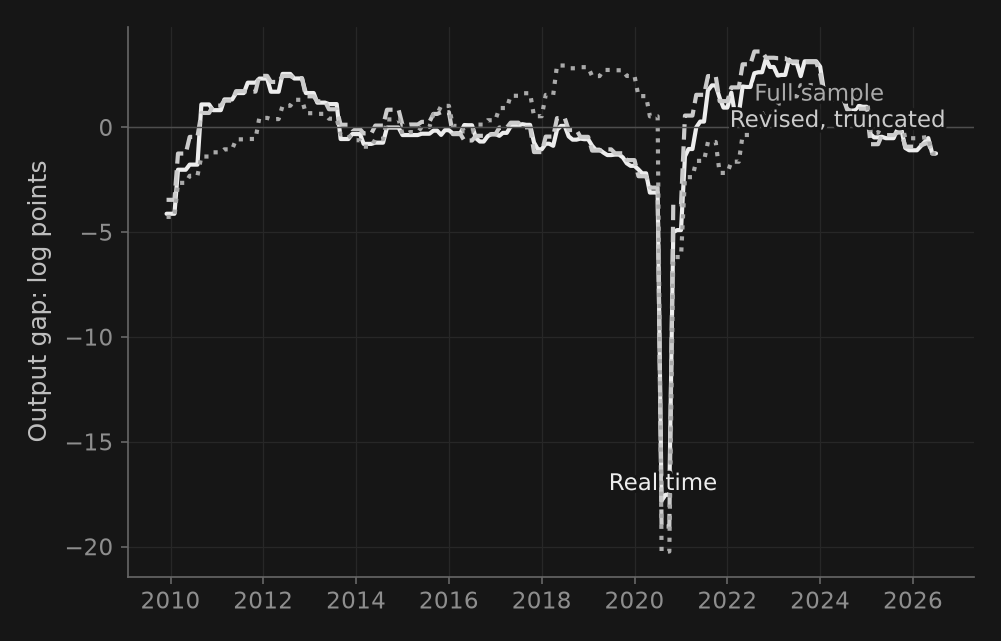

In [12]:
rt_country = "MEX"  # ← this exercise can be repeated for every archived country
levels = vintages.triangle(rt_country, transform="level")
latest = levels.iloc[:, -1].dropna()
records = []
for edition in levels.columns:
    observed = levels[edition].dropna()
    if len(observed) < 40 or observed.index.max() >= latest.index.max():
        continue
    dates = pd.date_range(observed.index.min(), observed.index.max(), freq="QS")
    rt = observed.reindex(dates)
    pseudo = latest.reindex(dates)
    full = latest.loc[dates.min():].asfreq("QS")
    if rt.isna().any() or pseudo.isna().any() or full.isna().any():
        continue
    t = dates[-1]
    grt = float(np.asarray(hp_filter(100*np.log(rt), lamb=1600)[0])[-1])
    gp = float(np.asarray(hp_filter(100*np.log(pseudo), lamb=1600)[0])[-1])
    gf = float(hp_filter(100*np.log(full), lamb=1600)[0].loc[t])
    records.append({"edition":edition,"quarter":t,"real_time":grt,"pseudo":gp,"full":gf,
                    "data_revision":gp-grt,"endpoint_revision":gf-gp,"total_revision":gf-grt})
revision_gap = pd.DataFrame(records).set_index("edition")
assert np.allclose(revision_gap.total_revision, revision_gap.data_revision+revision_gap.endpoint_revision)
display(revision_gap.tail(8).round({col:2 for col in revision_gap.tail(8).select_dtypes("number")}))
display(revision_gap[["data_revision","endpoint_revision","total_revision"]].agg(["mean","std"]).round(2))
print(tr("Sign disagreement:", "Desacuerdo de signo:"),
      round(100*np.mean(np.sign(revision_gap.real_time)!=np.sign(revision_gap.full)),1), "%")
fig, ax = _nbstyle.figura(1, 1)
for j, col in enumerate(["real_time", "pseudo", "full"]):
    ax.plot(revision_gap.index, revision_gap[col], color=cols[j], ls=["-","--",":"][j], label={"real_time":tr("Real time","Tiempo real"), "pseudo":tr("Revised, truncated","Revisado, truncado"), "full":tr("Full sample","Muestra completa"), "current":tr("Current vintage","Vintage actual")}[col])
ax.axhline(0, color=cols[-1], lw=.7)
ax.set_ylabel(tr("Output gap: log points", "Brecha: puntos logarítmicos"))
_nbstyle.etiquetar(ax); plt.show()

## 5. The Sahm signal and the information set

For monthly unemployment **in percentage points**, define
$$\bar u_t=\tfrac13(u_t+u_{t-1}+u_{t-2}),\qquad S_t=\bar u_t-\min_{j=1,\ldots,12}\bar u_{t-j}.$$
A U.S. signal occurs at $S_t\geq0.50$ percentage points. The trailing baseline excludes the current month; no value is rounded before thresholding. Reindex to calendar months before rolling, otherwise gaps shorten the effective window.

This is a change in unemployment, not the level of slack, and it is not an official recession declaration. A cross-country application of the same threshold is exploratory, not a validated universal rule. The next cell checks the calculation against **SAHMCURRENT** and contrasts it with **SAHMREALTIME**, which uses the historical information set. [FRED current-vintage definition](https://fred.stlouisfed.org/series/SAHMCURRENT), [real-time definition](https://fred.stlouisfed.org/series/SAHMREALTIME).

Largest reconstruction error (pp): 0.003333


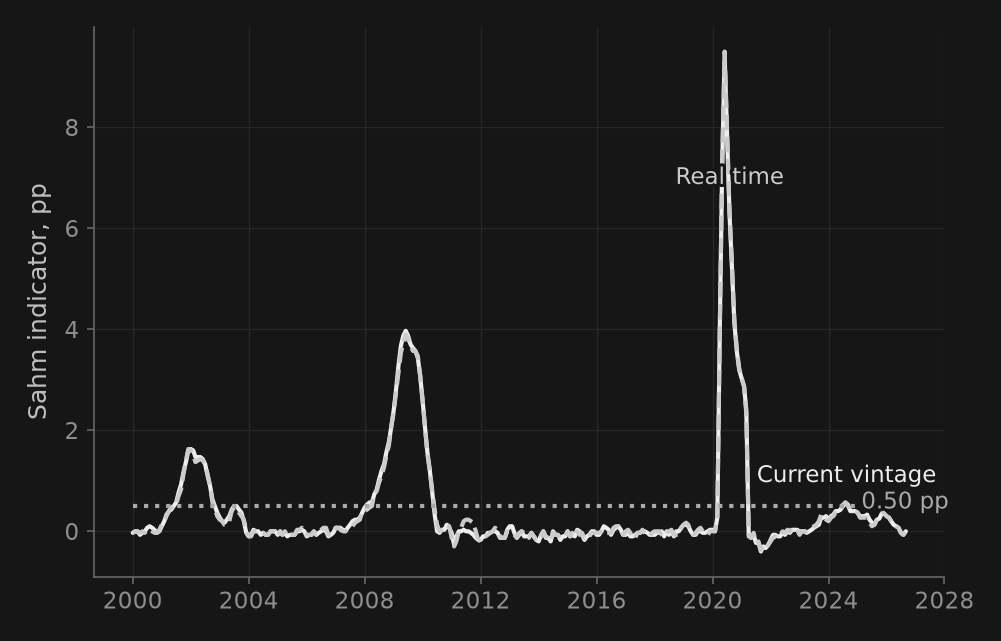

,calculated,current,real_time
2026-04-01,NaN,0.13,0.13
2026-05-01,NaN,0.10,0.10
2026-06-01,NaN,0.07,0.07
2026-07-01,NaN,-0.03,-0.03
2026-08-01,NaN,-0.07,-0.07
2026-09-01,NaN,0.00,0.00


In [13]:
from _t01 import sahm

def fred_snapshot(series):
    d = pd.read_csv(ruta_dato("t01_"+series+".csv"), parse_dates=["observation_date"])
    return pd.to_numeric(d.set_index("observation_date")[series], errors="coerce").asfreq("MS")
u = fred_snapshot("UNRATE")
sahm_check = pd.concat([sahm(u).rename("calculated"), fred_snapshot("SAHMCURRENT").rename("current"),
                        fred_snapshot("SAHMREALTIME").rename("real_time")], axis=1)
# FRED publishes the indicator to two decimals. Check with that publication tolerance.
max_error = (sahm_check.calculated-sahm_check.current).dropna().abs().max()
print(tr("Largest reconstruction error (pp):", "Error máximo de reconstrucción (pp):"), round(max_error,6))
assert max_error <= .011
fig, ax = _nbstyle.figura(1,1)
for j,col in enumerate(["current", "real_time"]):
    z = sahm_check.loc["2000":, col]
    ax.plot(z.index,z,color=cols[j],ls=["-","--"][j],label={"real_time":tr("Real time","Tiempo real"), "pseudo":tr("Revised, truncated","Revisado, truncado"), "full":tr("Full sample","Muestra completa"), "current":tr("Current vintage","Vintage actual")}[col])
ax.plot(z.index, np.full(len(z), .5), color=cols[2], ls=":", label="0.50 pp")
ax.set_ylabel(tr("Sahm indicator, pp", "Indicador de Sahm, pp"))
_nbstyle.etiquetar(ax);plt.show()
display(sahm_check.tail(6).round(3))

## 6. Where are we in the cycle — as described by these files?

Read **level relative to a statistical trend**, **growth**, and **labour deterioration** separately. A negative HP gap can coexist with positive growth; a low unemployment rate can coexist with a rising Sahm indicator. Industrial production covers a narrower sector than GDP. Do not average these concepts into an unlabeled “cycle score.”

The dashboard uses each series' latest usable observation and prints its reference date. It uses revised snapshots assembled for this lesson, **not** a reconstruction of information available on any historical decision date. Its GDP gap is an expanding-sample endpoint estimate using the latest data; it will move with the next release. Monthly publication edges can differ across countries. No causal inference or automatic recession label follows.

In [14]:
rows = []
for c in sorted(set(q.index.get_level_values("code")) | set(m.index.get_level_values("code"))):
    row = {"code":c}
    if c in q.index.get_level_values("code"):
        b = regular_block(q.loc[c], ["gdp_real"], min_obs=40, which="latest")
        if b is not None:
            y=100*np.log(b.gdp_real)
            row.update(gdp_quarter=str(y.index[-1].to_period("Q")),
                       gdp_growth_qoq=float(y.diff().iloc[-1]),
                       hp_endpoint=float(np.asarray(hp_filter(y,lamb=1600)[0])[-1]))
    if c in m.index.get_level_values("code"):
        z=m.loc[c].asfreq("MS")
        ip_growth=100*np.log(z.ip).diff(12).dropna()
        ur=z.urate.dropna()
        signal=sahm(z.urate).dropna()
        if not ip_growth.empty:
            row.update(ip_month=str(ip_growth.index[-1].to_period("M")),ip_growth_yoy=ip_growth.iloc[-1])
        if not ur.empty:
            row.update(urate_month=str(ur.index[-1].to_period("M")),urate=ur.iloc[-1])
        if not signal.empty:
            row.update(sahm_month=str(signal.index[-1].to_period("M")),sahm_pp=signal.iloc[-1],
                       above_US_threshold=bool(signal.iloc[-1]>=.5-1e-12))
    rows.append(row)
dashboard=pd.DataFrame(rows).set_index("code")
with pd.option_context("display.max_rows", None):  # every economy on screen, not a truncated sample
    display(dashboard.round(2))
print(tr("Missing cells remain missing; reference dates differ. No universal recession classification.",
         "Los faltantes siguen faltando; las fechas difieren. No es una clasificación universal de recesiones."))

,gdp_quarter,gdp_growth_qoq,hp_endpoint,ip_month,ip_growth_yoy,urate_month,urate,sahm_month,sahm_pp,above_US_threshold
code,,,,,,,,,,
ALB,2026Q1,0.76,-0.38,2026-06,5.54,NaN,NaN,NaN,NaN,NaN
ARG,2026Q2,-0.59,0.09,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ARM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AUS,2026Q2,0.42,-0.32,2021-01,3.67,2026-08,4.65,2026-08,0.36,False
AUT,2026Q2,-0.13,-0.49,2026-07,-1.91,2026-08,6.70,2026-08,0.50,True
BEL,2026Q2,0.03,-1.13,2026-07,-5.76,2026-08,5.90,2026-08,-0.03,False
BGR,2026Q2,0.66,-0.20,2026-07,-6.08,2026-08,3.50,2026-08,0.50,True
BIH,2026Q1,0.19,-1.05,2026-08,-0.23,2026-07,11.40,2026-07,0.00,False
BRA,2026Q2,0.48,-0.42,2026-08,-1.41,2015-11,8.01,2015-11,2.91,True


Missing cells remain missing; reference dates differ. No universal recession classification.


### 6.1 Dating and nowcasting belong here, identification comes later

Turning-point dating (such as Bry–Boschan) classifies peaks and troughs after applying duration rules; it does not estimate an output gap. A nowcast predicts the unobserved current quarter from a ragged monthly panel; it is not the same as forecasting the next quarter. A real-time evaluation must reproduce both vintage data and release dates, including parameter estimation using only available observations. Truncating a revised series is only a pseudo-real-time exercise.

The [frequency companion, §§1 and 4](T01_C_high_frequency.ipynb) retains the turning-point and MIDAS/factor-model laboratories. Its later local projections and monetary-policy instruments are optional bridges to Modules 3 and 5: predictive timing alone does not identify a causal shock.

## 7. Your turn

1. Re-estimate the revision tests with a 24-month maturity horizon. Which country classifications change? Separate bias from the slope restrictions.
2. Replace Mexico with Spain in the filter and vintage exercises. Compare methods on their **common dates**, and explain why BK cannot diagnose the latest quarter.
3. For one country, write a three-sentence cycle assessment: the observation dates, what growth and unemployment say, and what the indicators cannot establish.
4. Recompute Sahm after inserting one missing month. Verify that a gap does not silently become an adjacent observation.

### Solutions (outline)
A longer maturity horizon trades more revision information for a shorter sample. BK loses both endpoints; Hamilton fitted once is not a real-time residual history. A cycle assessment must distinguish level, growth and worsening labour conditions. Calendar reindexing propagates a missing month through the required rolling windows.

### Explore with AI
Give the tutor one dashboard row and ask for an interpretation that names every reference date, distinguishes revised from real-time data, and makes no causal or official recession claim.

**Next:** [C — long-run and short-run stylized facts](T01_C_stylized_facts.ipynb). We now have a declared measurement convention for the facts a model will have to explain.